# Supervised learning: predicting student dropout

**Goal:** predict whether a student will *Dropout*, stay *Enrolled* or *Graduate* (3 classes) using the UCI dataset "Predict Students' Dropout and Academic Success" (id=697).

This notebook is built up in blocks. This first part is exploratory data analysis (EDA): I want to understand the data before I model it.

## 1. Load the data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo

# Download the dataset from the UCI repository (id=697)
dataset = fetch_ucirepo(id=697)

X = dataset.data.features          # the 36 input columns
y = dataset.data.targets["Target"] # the label: Dropout / Enrolled / Graduate

print("Features shape:", X.shape)
print("Target shape:  ", y.shape)

Features shape: (4424, 36)
Target shape:   (4424,)


In [2]:
# First 5 rows (transposed so all 36 columns fit on screen)
X.head().T

,0,1,2,3,4
Marital Status,1.00,1.000000,1.00,1.000000,2.000000
Application mode,17.00,15.000000,1.00,17.000000,39.000000
Application order,5.00,1.000000,5.00,2.000000,1.000000
Course,171.00,9254.000000,9070.00,9773.000000,8014.000000
Daytime/evening attendance,1.00,1.000000,1.00,1.000000,0.000000
Previous qualification,1.00,1.000000,1.00,1.000000,1.000000
Previous qualification (grade),122.00,160.000000,122.00,122.000000,100.000000
Nacionality,1.00,1.000000,1.00,1.000000,1.000000
Mother's qualification,19.00,1.000000,37.00,38.000000,37.000000
Father's qualification,12.00,3.000000,37.00,37.000000,38.000000


## 2. Data types and missing values

In [3]:
# How many columns of each type?
print(X.dtypes.value_counts())

int64      29
float64     7
Name: count, dtype: int64


In [4]:
# Missing values and duplicates
print("Total missing values in features:", X.isna().sum().sum())
print("Missing values in target:        ", y.isna().sum())
print("Duplicate rows in features:      ", X.duplicated().sum())

Total missing values in features: 0
Missing values in target:         0
Duplicate rows in features:       0


There are no missing values and no duplicate rows, so no cleaning is needed. Most columns are stored as integers (`int64`), but as I show below, many of those integers are really **category codes**, not quantities.

In [5]:
# Number of distinct values per column helps me spot codes vs real numbers
X.nunique().sort_values()

Daytime/evening attendance                          2
Displaced                                           2
Debtor                                              2
Educational special needs                           2
International                                       2
Scholarship holder                                  2
Gender                                              2
Tuition fees up to date                             2
Marital Status                                      6
Application order                                   8
Inflation rate                                      9
Curricular units 2nd sem (without evaluations)     10
GDP                                                10
Unemployment rate                                  10
Curricular units 1st sem (without evaluations)     11
Previous qualification                             17
Course                                             17
Application mode                                   18
Curricular units 2nd sem (cr

## 3. Class balance

          count  percent
Target                  
Graduate   2209     49.9
Dropout    1421     32.1
Enrolled    794     17.9


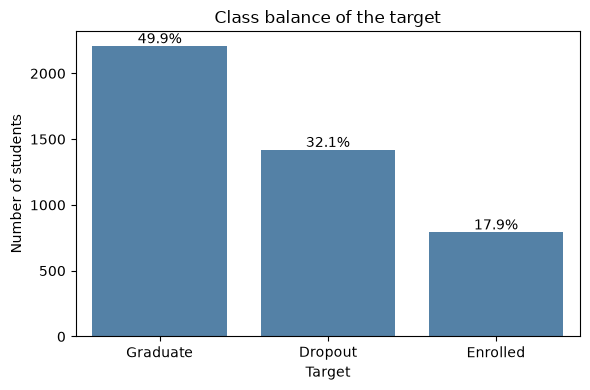

In [6]:
counts = y.value_counts()
percent = (y.value_counts(normalize=True) * 100).round(1)
print(pd.DataFrame({"count": counts, "percent": percent}))

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(x=y, order=counts.index, ax=ax, color="steelblue")
ax.set_title("Class balance of the target")
ax.set_xlabel("Target")
ax.set_ylabel("Number of students")

# Write the percentage above each bar
for i, label in enumerate(counts.index):
    ax.text(i, counts[label] + 20, f"{percent[label]}%", ha="center")

plt.tight_layout()
plt.savefig("../figures/class_balance.png", dpi=150)
plt.show()

The classes are imbalanced: about 50% Graduate, 32% Dropout and 18% Enrolled. This matters later: a model that always says "Graduate" would already be ~50% accurate, and "Enrolled" is the smallest class so it will be hardest to learn.

## 4. Which integer columns are really categorical codes?

A column like `Course` holds numbers such as 33, 171, 9500. These are just labels for different courses. Course 9500 is not "bigger" than course 171, so treating it as a number would be wrong for a linear model. I picked these columns by reading the dataset description and checking that they have many distinct values with no natural order.

I did **not** include:
- *Binary flags* (Gender, Debtor, Scholarship holder, ...): they are already 0/1, so they work fine as numbers.
- *Application order* (0-9): this is a real ranking (first choice, second choice, ...), so it is ordinal and fine as a number.
- *Daytime/evening attendance*: already a 0/1 flag.

In [7]:
# Integer columns that are really category codes.
# NOTE: the dataset spells "Nacionality" this way, so I keep its spelling.
categorical_code_cols = [
    "Marital Status",
    "Application mode",
    "Course",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation",
]

# Everything else is treated as a numeric feature
numeric_cols = [col for col in X.columns if col not in categorical_code_cols]

print(len(categorical_code_cols), "categorical-code columns")
print(len(numeric_cols), "numeric columns")
X[categorical_code_cols].nunique()

9 categorical-code columns
27 numeric columns


Marital Status             6
Application mode          18
Course                    17
Previous qualification    17
Nacionality               21
Mother's qualification    29
Father's qualification    34
Mother's occupation       32
Father's occupation       46
dtype: int64

## 5. Summary of EDA findings

- **Size:** 4,424 students and 36 features (29 integer, 7 float).
- **Data quality:** no missing values and no duplicate rows, so no imputation is needed.
- **Class imbalance:** Graduate ~50%, Dropout ~32%, Enrolled ~18%. Accuracy alone will be misleading, so I will also report macro F1 and Dropout recall.
- **Categorical codes:** 9 integer columns (marital status, application mode, course, previous qualification, nationality, and mother's/father's qualification and occupation) are labels, not quantities. I stored them in `categorical_code_cols` and will one-hot encode them for logistic regression.
- **Something to watch (leakage):** the 1st and 2nd semester "curricular units" columns describe how the student did *after* enrolling. They will probably be very predictive, but they are not available at enrolment time. I will test this in the Random Forest block.

---
# Baselines

Before building a Random Forest I need baselines to beat. Without them, a score like "75% accuracy" has no meaning.

1. **Naive baseline:** always predict the most common class (no learning at all).
2. **Simple baseline:** logistic regression, a basic linear model.

## 6. Train/test split

I split 80/20 and keep the class proportions the same in both parts (`stratify=y`). This matters because Enrolled is only ~18% of the data.

**Rule I am following:** the 20% test set is touched **once**, at the end (Block 5), to give the final scores. All the decisions in between (which model, which settings) are made using only the training set. If I peeked at the test set while choosing, the final scores would be too optimistic.

Because of that rule, the baseline scores below are measured with **5-fold cross-validation on the training set**: the training data is split into 5 parts, and each part is predicted by a model that never saw it.

In [8]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import accuracy_score, f1_score, recall_score, classification_report, confusion_matrix

# stratify=y keeps the 50/32/18 class split the same in train and test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Train:", X_train.shape, " Test:", X_test.shape)
print()
print("Train class %:")
print((y_train.value_counts(normalize=True) * 100).round(1))
print("Test class %:")
print((y_test.value_counts(normalize=True) * 100).round(1))

Train: (3539, 36)  Test: (885, 36)

Train class %:
Target
Graduate    49.9
Dropout     32.1
Enrolled    17.9
Name: proportion, dtype: float64
Test class %:
Target
Graduate    49.9
Dropout     32.1
Enrolled    18.0
Name: proportion, dtype: float64


In [9]:
# One cross-validation setup used for every model, so scores are comparable.
# shuffle=True because the rows may be ordered; random_state makes it repeatable.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def score_with_cv(model, name):
    """Out-of-fold predictions on the TRAIN set only. Returns the 3 headline metrics."""
    # Each training row is predicted by a model that did not see that row
    predictions = cross_val_predict(model, X_train, y_train, cv=cv)

    accuracy = accuracy_score(y_train, predictions)
    macro_f1 = f1_score(y_train, predictions, average="macro")
    # recall for the Dropout class only: of the real dropouts, how many did we catch?
    dropout_recall = recall_score(y_train, predictions, labels=["Dropout"], average=None)[0]

    print(name)
    print(f"  accuracy: {accuracy:.3f}   macro F1: {macro_f1:.3f}   Dropout recall: {dropout_recall:.3f}")
    print()
    # zero_division=0 stops warnings when a class is never predicted (the dummy case)
    print(classification_report(y_train, predictions, zero_division=0))
    return predictions

## 7. Naive baseline: always predict the most common class

In [10]:
dummy = DummyClassifier(strategy="most_frequent")
dummy_predictions = score_with_cv(dummy, "Dummy (most frequent)")

Dummy (most frequent)
  accuracy: 0.499   macro F1: 0.222   Dropout recall: 0.000

              precision    recall  f1-score   support

     Dropout       0.00      0.00      0.00      1137
    Enrolled       0.00      0.00      0.00       635
    Graduate       0.50      1.00      0.67      1767

    accuracy                           0.50      3539
   macro avg       0.17      0.33      0.22      3539
weighted avg       0.25      0.50      0.33      3539



## 8. Simple baseline: logistic regression

Logistic regression needs numbers it can multiply by weights, so the data has to be prepared:
- **Categorical codes** (`categorical_code_cols`) are one-hot encoded.
- **Numeric columns** are standardised (mean 0, std 1).

I put both steps inside a `Pipeline` with a `ColumnTransformer`. This is important: the encoder and scaler are then re-fitted **inside each cross-validation fold** using only that fold's training part, so no information leaks from the held-out part.

In [11]:
preprocessor = ColumnTransformer(
    transformers=[
        # handle_unknown="ignore": if a rare code (e.g. an unusual occupation) only appears
        # in the held-out fold, give it all zeros instead of crashing
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_code_cols),
        # scaling puts numeric columns on the same scale so none dominates just by its units
        ("numeric", StandardScaler(), numeric_cols),
    ]
)

logreg = Pipeline(
    steps=[
        ("preprocess", preprocessor),
        # max_iter raised because the default 100 may stop before the solver converges
        ("model", LogisticRegression(max_iter=1000, random_state=42)),
    ]
)

logreg_predictions = score_with_cv(logreg, "Logistic regression")

Logistic regression
  accuracy: 0.777   macro F1: 0.702   Dropout recall: 0.774

              precision    recall  f1-score   support

     Dropout       0.80      0.77      0.79      1137
    Enrolled       0.58      0.38      0.46       635
    Graduate       0.80      0.92      0.86      1767

    accuracy                           0.78      3539
   macro avg       0.73      0.69      0.70      3539
weighted avg       0.76      0.78      0.76      3539



In [12]:
# Which classes does logistic regression confuse? Rows = true class, columns = predicted.
labels = ["Dropout", "Enrolled", "Graduate"]
pd.DataFrame(
    confusion_matrix(y_train, logreg_predictions, labels=labels),
    index=["true " + l for l in labels],
    columns=["pred " + l for l in labels],
)

,pred Dropout,pred Enrolled,pred Graduate
true Dropout,880,101,156
true Enrolled,153,244,238
true Graduate,64,78,1625


## 9. Why one-hot encoding for logistic regression but not for Random Forest?

- **Logistic regression** gives each column a single weight and multiplies it by the column's value. If `Course` is one column holding 33, 171, 9500, the model would assume 9500 is "more" of something than 171 and would need one weight for the whole scale. That is meaningless for labels. One-hot encoding gives every course its own 0/1 column, so each course gets its own weight.
- **Random Forest** is made of decision trees that ask yes/no questions like "is Course <= 9000?". A tree can ask several such questions in a row and so can isolate any single course code, so it does not rely on the numbers having a real order. It also does not care about the scale of a column, so no scaling is needed either. (One-hot encoding can still be used with trees, but it is not required, and I keep the forest simple.)

## 10. Why accuracy is misleading here

About half the students are Graduates. The dummy model that **always** says "Graduate" gets about 50% accuracy while never finding a single Dropout or Enrolled student. Its Dropout recall and macro F1 expose that.

So I report three numbers:
- **Accuracy:** easy to read, but dominated by the biggest class.
- **Macro F1:** the average of the F1 of each class, with every class counting equally. A model that ignores Enrolled gets punished.
- **Dropout recall:** the share of real dropouts that the model catches. This is the number a university cares about, because the point of the model is to help students *before* they leave, and a missed dropout is the costly mistake.

All baseline scores above come from the training set only; test-set scores come in Block 5.

---
# Tuned Random Forest

A Random Forest is many decision trees trained on random resamples of the data, whose votes are combined. I tune three settings with a grid search and compare two versions of the feature set.

## 11. Grid search

I try every combination of:
- `n_estimators` (number of trees): 100, 300
- `max_depth` (how many questions a tree may ask in a row): None (unlimited), 10, 20
- `min_samples_leaf` (minimum students in a final leaf): 1, 3, 5

That is 2 x 3 x 3 = 18 combinations, each scored with the same 5-fold stratified CV, so 90 model fits per version. I score with `f1_macro` instead of accuracy because of the class imbalance, and use `class_weight="balanced"` so mistakes on the small Enrolled class cost more during training.

No one-hot encoding or scaling here: trees do not need it (see section 9). The search only ever sees the **training** set.

In [13]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [100, 300],
    "max_depth": [None, 10, 20],
    "min_samples_leaf": [1, 3, 5],
}

def tune_forest(X_tr, y_tr):
    """Grid search a balanced Random Forest and return the fitted search object."""
    forest = RandomForestClassifier(class_weight="balanced", random_state=42)
    search = GridSearchCV(
        forest,
        param_grid,
        cv=cv,                # same folds as the baselines
        scoring="f1_macro",
        n_jobs=-1,            # use all CPU cores; only changes speed, not the result
    )
    search.fit(X_tr, y_tr)    # refit=True (default) retrains the best setting on all training rows
    return search

## 12. Two versions of the feature set

- **(a) All features.**
- **(b) Without the 1st/2nd semester curricular-unit columns.** These 12 columns say how many courses the student enrolled in, passed and was graded on during the first two semesters. They are only known *after* the student has already been studying for a year. If the goal is to flag at-risk students **at enrolment**, version (a) is using information from the future. This is a form of **data leakage** (the model uses information that would not exist at prediction time), so version (b) is the realistic one.

In [14]:
# Version (b): drop every column that describes semester performance
semester_cols = [col for col in X.columns if "Curricular units" in col]
print(len(semester_cols), "semester columns dropped for version (b):")
for col in semester_cols:
    print("  -", col)

X_train_nosem = X_train.drop(columns=semester_cols)
print()
print("Version (a) shape:", X_train.shape)
print("Version (b) shape:", X_train_nosem.shape)

12 semester columns dropped for version (b):
  - Curricular units 1st sem (credited)
  - Curricular units 1st sem (enrolled)
  - Curricular units 1st sem (evaluations)
  - Curricular units 1st sem (approved)
  - Curricular units 1st sem (grade)
  - Curricular units 1st sem (without evaluations)
  - Curricular units 2nd sem (credited)
  - Curricular units 2nd sem (enrolled)
  - Curricular units 2nd sem (evaluations)
  - Curricular units 2nd sem (approved)
  - Curricular units 2nd sem (grade)
  - Curricular units 2nd sem (without evaluations)

Version (a) shape: (3539, 36)
Version (b) shape: (3539, 24)


In [15]:
# (a) all features
search_all = tune_forest(X_train, y_train)
print("(a) ALL FEATURES")
print("  best params:  ", search_all.best_params_)
print(f"  best CV macro F1: {search_all.best_score_:.3f}")

(a) ALL FEATURES
  best params:   {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 100}
  best CV macro F1: 0.717


In [16]:
# (b) without semester columns
search_nosem = tune_forest(X_train_nosem, y_train)
print("(b) WITHOUT SEMESTER COLUMNS")
print("  best params:  ", search_nosem.best_params_)
print(f"  best CV macro F1: {search_nosem.best_score_:.3f}")

(b) WITHOUT SEMESTER COLUMNS
  best params:   {'max_depth': 20, 'min_samples_leaf': 3, 'n_estimators': 300}
  best CV macro F1: 0.586


In [17]:
# Look at the whole grid for version (a) to see how the settings matter
grid_results = pd.DataFrame(search_all.cv_results_)[
    ["param_n_estimators", "param_max_depth", "param_min_samples_leaf", "mean_test_score", "std_test_score"]
]
grid_results.sort_values("mean_test_score", ascending=False).round(3).reset_index(drop=True)

,param_n_estimators,param_max_depth,param_min_samples_leaf,mean_test_score,std_test_score
0,100,None,1,0.717,0.015
1,300,10,5,0.717,0.017
2,300,20,5,0.716,0.015
3,300,None,1,0.716,0.011
4,300,10,1,0.716,0.016
5,100,10,3,0.715,0.020
6,300,None,5,0.715,0.015
7,300,10,3,0.714,0.019
8,100,10,5,0.714,0.014
9,100,None,3,0.714,0.010


## 13. Confusion matrices and feature importances

Again I do not touch the test set. The confusion matrices use **cross-validated predictions on the training set**, made with each version's best settings. The feature importances come from the best model fitted on the training set.

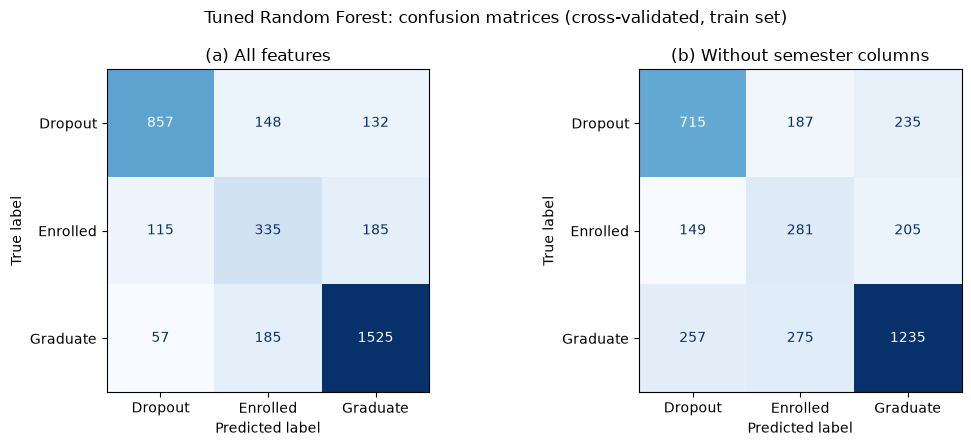

In [18]:
from sklearn.metrics import ConfusionMatrixDisplay

best_all = search_all.best_estimator_
best_nosem = search_nosem.best_estimator_

# Out-of-fold predictions: every training row is predicted by a forest that did not see it
pred_all = cross_val_predict(best_all, X_train, y_train, cv=cv)
pred_nosem = cross_val_predict(best_nosem, X_train_nosem, y_train, cv=cv)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, predictions, title in [
    (axes[0], pred_all, "(a) All features"),
    (axes[1], pred_nosem, "(b) Without semester columns"),
]:
    ConfusionMatrixDisplay.from_predictions(
        y_train, predictions, labels=labels, ax=ax, cmap="Blues", colorbar=False
    )
    ax.set_title(title)

plt.suptitle("Tuned Random Forest: confusion matrices (cross-validated, train set)")
plt.tight_layout()
plt.savefig("../figures/rf_confusion_matrices.png", dpi=150)
plt.show()

In [19]:
print("(a) All features")
print(classification_report(y_train, pred_all))
print("(b) Without semester columns")
print(classification_report(y_train, pred_nosem))

(a) All features
              precision    recall  f1-score   support

     Dropout       0.83      0.75      0.79      1137
    Enrolled       0.50      0.53      0.51       635
    Graduate       0.83      0.86      0.85      1767

    accuracy                           0.77      3539
   macro avg       0.72      0.71      0.72      3539
weighted avg       0.77      0.77      0.77      3539

(b) Without semester columns
              precision    recall  f1-score   support

     Dropout       0.64      0.63      0.63      1137
    Enrolled       0.38      0.44      0.41       635
    Graduate       0.74      0.70      0.72      1767

    accuracy                           0.63      3539
   macro avg       0.58      0.59      0.59      3539
weighted avg       0.64      0.63      0.63      3539



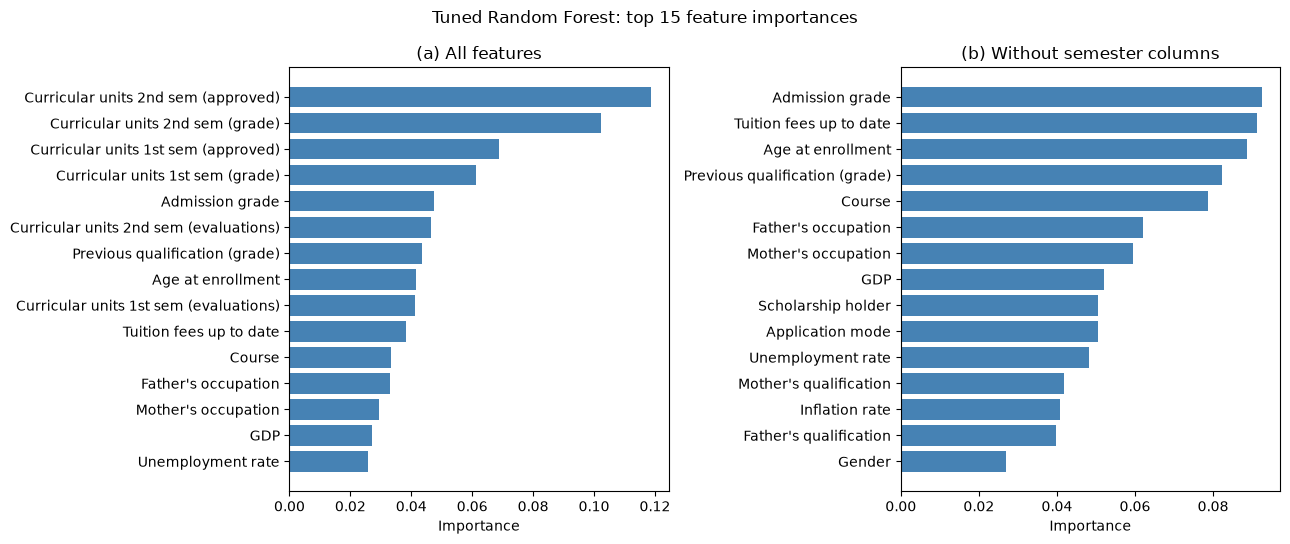

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, model, columns, title in [
    (axes[0], best_all, X_train.columns, "(a) All features"),
    (axes[1], best_nosem, X_train_nosem.columns, "(b) Without semester columns"),
]:
    importances = pd.Series(model.feature_importances_, index=columns)
    top15 = importances.sort_values(ascending=False).head(15)
    # [::-1] so the most important feature is drawn at the top of the bar chart
    ax.barh(top15.index[::-1], top15.values[::-1], color="steelblue")
    ax.set_title(title)
    ax.set_xlabel("Importance")

plt.suptitle("Tuned Random Forest: top 15 feature importances")
plt.tight_layout()
plt.savefig("../figures/rf_feature_importances.png", dpi=150)
plt.show()

## 14. What the results mean

**Best parameters**

| Version | n_estimators | max_depth | min_samples_leaf | CV macro F1 |
|---|---|---|---|---|
| (a) all features | 100 | None | 1 | 0.717 |
| (b) without semester columns | 300 | 20 | 3 | 0.586 |

- **(a) chose the least restricted forest:** unlimited depth and leaves of size 1. Each single tree is allowed to grow until it memorises its training sample. That is fine here because a forest averages many such trees, and the averaging cancels much of that memorisation (I measure this properly in Block 5).
- **(b) chose a more restricted forest** (depth 20, at least 3 students per leaf). Without the semester columns the signal is weaker and noisier, so it helps to stop trees from chasing noise.
- **The grid is very flat.** In version (a) all 18 settings scored between 0.708 and 0.717, and the fold-to-fold standard deviation is about 0.015. So the "best" setting is only slightly better than the others, and I should not read much into which one won. The number of trees and the exact depth matter much less than which features I give the model.

**How good is it?** With all features the tuned forest has a cross-validated macro F1 of 0.717, versus 0.702 for logistic regression. That is a small gain, about the same size as the fold-to-fold noise, so I will not claim a clear win until I see the test-set numbers in Block 5. The Enrolled class does get better: F1 0.51 vs 0.46 for logistic regression, with recall 0.53 vs 0.38. This is partly because of `class_weight="balanced"`. Dropout recall is 0.75 compared with 0.77 for logistic regression, so the forest is slightly worse at catching dropouts.

**Feature importances.** In version (a) the top four features are all semester curricular-unit columns (2nd sem approved, 2nd sem grade, 1st sem approved, 1st sem grade). A student who passes few courses is much more likely to drop out, which is intuitive. Impurity-based importances tend to favour columns with many distinct values (like grades), so I read them as a rough guide, not exact effects.

**Leakage discussion.** Version (a) looks good but only because it is allowed to see the students' first two semesters of results.
- Dropping those 12 columns drops macro F1 from **0.717 to 0.586** and Dropout recall from 0.75 to 0.63. Accuracy falls from 0.77 to 0.63.
- Version (b) is the honest estimate of what we could predict **at enrolment**. When I removed the semester columns the top features became admission grade, tuition fees up to date, age at enrolment, previous qualification grade and course.
- So the answer depends on *when* the university wants to act. At enrolment, the realistic model is weak (0.586 is well above the 0.222 dummy, but not accurate enough to act on alone). After one or two semesters, the strong version (a) becomes valid, because by then those columns are known. Calling (a) a "dropout predictor at enrolment" would be misleading.
- Note that "tuition fees up to date" is also only known after some months, so even version (b) is slightly generous.
